# Sensitivity analysis: how defensible is the peak reduction?

The core result (67% median peak reduction at JPL) assumed **every car can draw 6.656 kW**. Real cars often can't: their on-board charger is the bottleneck. This notebook tests how the result moves when we change:

| Scenario | What changes |
|---|---|
| `jpl_base` | Core assumption: every car 6.656 kW (32 A × 208 V) |
| `jpl_observed` | **Each car's max rate estimated from its own observed charging** (user's 90th-percentile rate; see `acn/rates.py`) |
| `jpl_charger_5.0kW`, `jpl_charger_3.3kW` | Every car limited to 5.0 or 3.3 kW (charger-max sweep) |
| `jpl_observed_rmin_6A/8A/16A` | Observed rates + a minimum charging rate of 1.25 / 1.66 / 3.33 kW |
| `caltech_base`, `caltech_observed` | Same model at the Caltech garage |

Window: 2019-01-01 → 2020-02-29 (pre-COVID). Summaries use weekdays with at least 5 sessions. Produced by `python -m acn.sensitivity`.

**Peak "needed to deliver 100% of energy"**:
- uncontrolled and LP: their own peaks, since both deliver everything;
- equal sharing: the smallest site cap at which it delivers everything (bisection).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display

from acn import plots
plots.style()
pd.set_option("display.precision", 2)
FIGS = ROOT / "results" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight")

from acn.sensitivity import SCENARIOS

frames = []
for name, sc in SCENARIOS.items():
    f = ROOT / "results" / "sensitivity" / f"{name}.csv"
    if f.exists():
        d = pd.read_csv(f)
        d["r_min_kw"] = sc.r_min_kw
        frames.append(d)
allres = pd.concat(frames, ignore_index=True)
allres["date"] = pd.to_datetime(allres["date"])
wk = allres[allres["weekday"].isin(plots.WEEKDAYS) & (allres["n_sessions"] >= 5)].copy()
print(wk.groupby("scenario").size().rename("weekdays used"))

scenario
caltech_base             300
caltech_observed         300
jpl_base                 297
jpl_charger_3.3kW        297
jpl_charger_5.0kW        297
jpl_observed             297
jpl_observed_rmin_16A    297
jpl_observed_rmin_6A     297
jpl_observed_rmin_8A     297
Name: weekdays used, dtype: int64


## 1. Summary table, with bootstrap 95% confidence intervals on the median reduction

In [2]:
rng = np.random.default_rng(0)

def boot_ci(x, n=2000):
    x = np.asarray(x)
    meds = np.median(rng.choice(x, size=(n, len(x)), replace=True), axis=1)
    return np.percentile(meds, [2.5, 97.5])

rows = []
for name in SCENARIOS:
    d = wk[wk["scenario"] == name]
    if d.empty:
        continue
    red_eq = 1 - d["peak_equal_share_min_kw"] / d["peak_uncontrolled_kw"]
    lo, hi = boot_ci(d["peak_reduction"])
    rows.append({
        "scenario": name, "note": SCENARIOS[name].note,
        "mean car rate (kW)": d["mean_car_rate_kw"].mean(),
        "uncontrolled peak": d["peak_uncontrolled_kw"].median(),
        "equal-sharing peak": d["peak_equal_share_min_kw"].median(),
        "LP peak": d["peak_lp_kw"].median(),
        "LP reduction": d["peak_reduction"].median(),
        "LP reduction 95% CI": f"[{lo:.1%}, {hi:.1%}]",
        "eq-share reduction": red_eq.median(),
        "eq-share unmet at LP cap": d["unmet_equal_share_at_lp_frac"].median(),
        "energy clipped": d["kwh_clipped"].sum() / (d["energy_kwh"].sum() + d["kwh_clipped"].sum()),
    })
summary = pd.DataFrame(rows).set_index("scenario")
display(summary.style.format({c: "{:.1%}" for c in ["LP reduction", "eq-share reduction",
                                                     "eq-share unmet at LP cap", "energy clipped"]}
                             | {c: "{:.0f}" for c in ["uncontrolled peak", "equal-sharing peak", "LP peak"]}
                             | {"mean car rate (kW)": "{:.2f}"}))

,note,mean car rate (kW),uncontrolled peak,equal-sharing peak,LP peak,LP reduction,LP reduction 95% CI,eq-share reduction,eq-share unmet at LP cap,energy clipped
scenario,,,,,,,,,,
jpl_base,every car 6.656 kW (32 A),6.66,254,144,81,67.1%,"[66.6%, 67.6%]",40.0%,8.6%,0.0%
jpl_observed,per-car rate from observed charging,4.60,210,166,84,58.5%,"[58.1%, 59.2%]",14.8%,8.2%,0.0%
jpl_charger_5.0kW,every car 5.0 kW,5.00,213,210,82,60.1%,"[59.5%, 60.8%]",0.4%,8.9%,2.6%
jpl_charger_3.3kW,every car 3.3 kW,3.30,152,152,75,48.6%,"[47.9%, 49.3%]",0.1%,8.9%,13.6%
jpl_observed_rmin_6A,observed + min 6 A (1.25 kW),4.60,210,166,86,57.6%,"[56.7%, 58.0%]",14.8%,7.0%,0.0%
jpl_observed_rmin_8A,observed + min 8 A (1.66 kW),4.60,210,166,87,57.0%,"[56.3%, 57.6%]",14.8%,6.5%,0.0%
jpl_observed_rmin_16A,observed + min 16 A (3.33 kW),4.60,210,166,128,38.6%,"[38.1%, 39.0%]",14.8%,1.0%,0.0%
caltech_base,every car 6.656 kW,6.66,73,50,24,66.8%,"[66.1%, 67.6%]",26.1%,14.2%,0.1%
caltech_observed,per-car rate from observed charging,4.17,66,51,24,62.9%,"[61.9%, 63.8%]",18.6%,13.2%,0.1%


**Reading the table.**
- *Energy clipped* is the share of delivered energy that could not physically fit at that scenario's rate limit and was removed from the target.
- In the 3.3 kW scenario, that clipping (not better scheduling) is part of why its LP peak is lower. Compare scenarios with high clipping cautiously.
- The confidence interval is on the *median* across weekdays, resampling days with replacement. It does not include modelling uncertainty such as the rate assumption; that is what the scenarios are for.

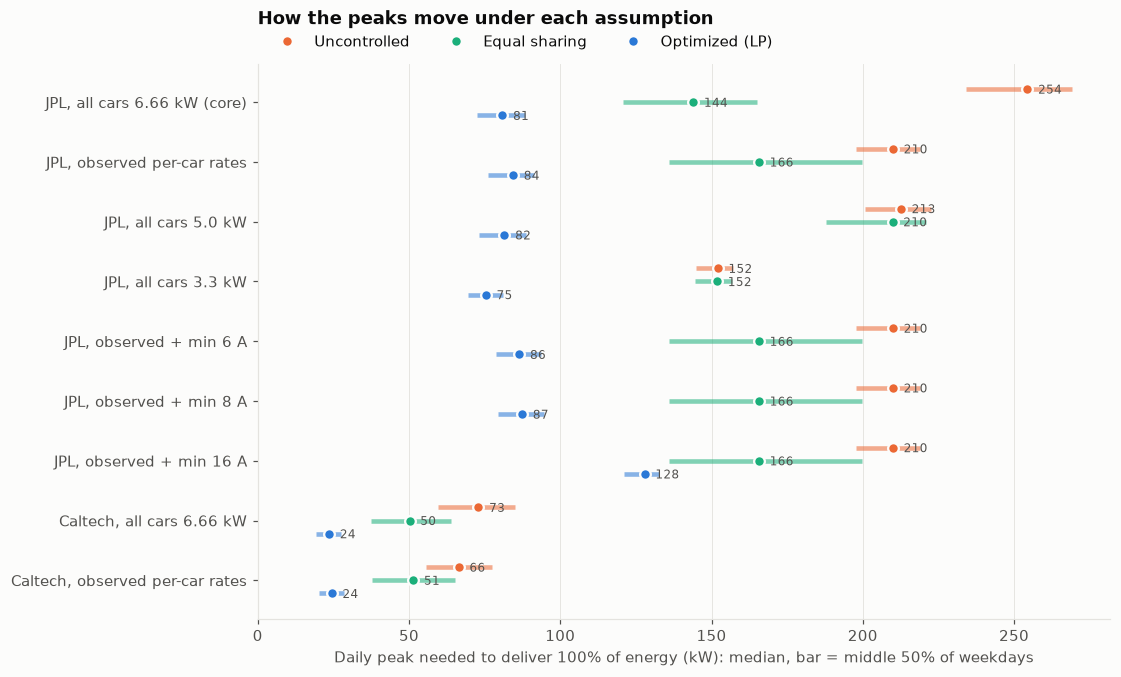

In [3]:
labels = {
    "jpl_base": "JPL, all cars 6.66 kW (core)", "jpl_observed": "JPL, observed per-car rates",
    "jpl_charger_5.0kW": "JPL, all cars 5.0 kW", "jpl_charger_3.3kW": "JPL, all cars 3.3 kW",
    "jpl_observed_rmin_6A": "JPL, observed + min 6 A", "jpl_observed_rmin_8A": "JPL, observed + min 8 A",
    "jpl_observed_rmin_16A": "JPL, observed + min 16 A",
    "caltech_base": "Caltech, all cars 6.66 kW", "caltech_observed": "Caltech, observed per-car rates",
}
long = []
for name in summary.index:
    d = wk[wk["scenario"] == name]
    for k, col in [("uncontrolled", "peak_uncontrolled_kw"), ("equal_share", "peak_equal_share_min_kw"),
                   ("lp", "peak_lp_kw")]:
        q = d[col].quantile([0.25, 0.5, 0.75]).to_numpy()
        long.append({"label": labels[name], "method": k, "q25": q[0], "q50": q[1], "q75": q[2]})
fig = plots.scenario_peaks(pd.DataFrame(long))
save(fig, "sensitivity_peaks")

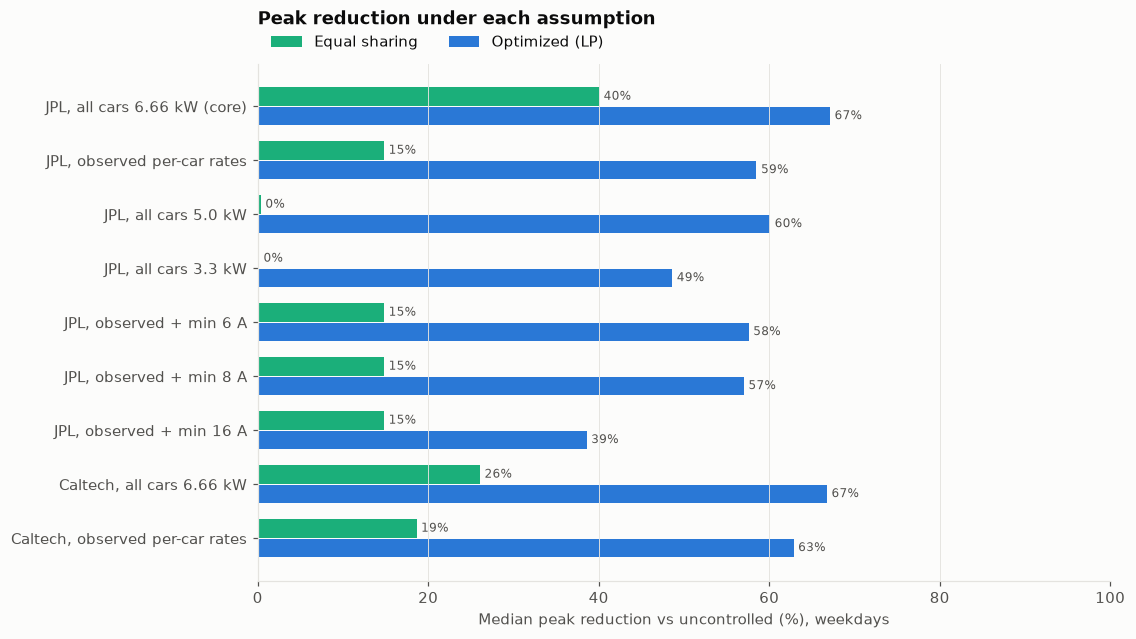

In [4]:
red = summary.rename(index=labels)[["eq-share reduction", "LP reduction"]].rename(
    columns={"eq-share reduction": "red_equal_share", "LP reduction": "red_lp"}).reset_index(names="label")
fig = plots.scenario_reductions(red)
save(fig, "sensitivity_reductions")

## 2. Minimum charging rate

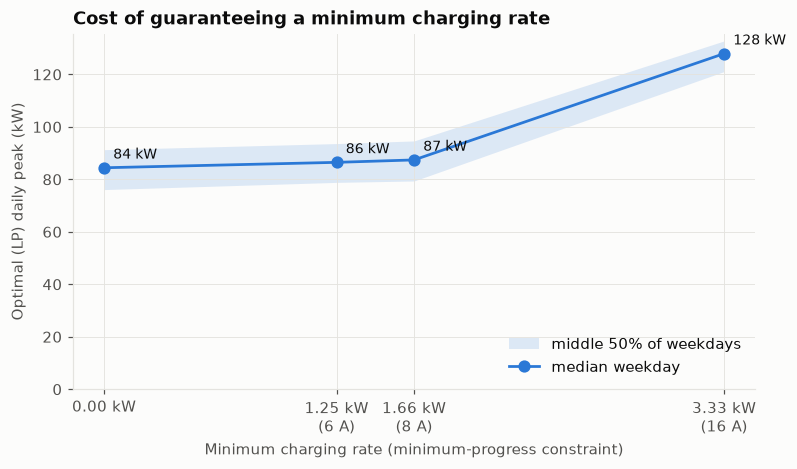

In [5]:
rm = wk[wk["scenario"].isin(["jpl_observed", "jpl_observed_rmin_6A", "jpl_observed_rmin_8A",
                              "jpl_observed_rmin_16A"])]
fig = plots.rmin_effect(rm)
save(fig, "sensitivity_rmin")

The minimum-rate guarantee is modelled as **minimum progress**: a car that leaves at any moment has at least what charging at $r_{\min}$ would have given it, capped at its need, and slow cars are only held to their own max rate.
- Hardware-level minimums (6–8 A) cost little peak: the LP mostly charges cars steadily anyway.
- A 16 A guarantee forces early charging and costs more.

## 3. Day types: Monday–Thursday, Fridays, weekends

In [6]:
obs = allres[(allres["scenario"] == "jpl_observed") & (allres["n_sessions"] >= 5)].copy()
obs["day type"] = np.select([obs["weekday"].isin(["Saturday", "Sunday"]), obs["weekday"] == "Friday"],
                            ["weekend", "Friday"], "Mon-Thu")
obs["Friday kind"] = np.where(obs["weekday"] != "Friday", "",
                              np.where(obs["n_sessions"] >= 50, "busy Friday", "quiet Friday"))
g = obs.assign(kind=np.where(obs["Friday kind"] != "", obs["Friday kind"], obs["day type"])).groupby("kind")
display(g.agg(days=("date", "size"), sessions=("n_sessions", "median"),
              uncontrolled_kw=("peak_uncontrolled_kw", "median"), lp_kw=("peak_lp_kw", "median"),
              reduction=("peak_reduction", "median")).reindex(["Mon-Thu", "busy Friday", "quiet Friday", "weekend"]))

,days,sessions,uncontrolled_kw,lp_kw,reduction
kind,,,,,
Mon-Thu,237,72.0,211.69,84.98,0.59
busy Friday,28,75.0,211.80,90.11,0.58
quiet Friday,32,31.5,65.33,34.62,0.46
weekend,43,6.0,15.40,10.70,0.33


Busy Fridays look like Monday–Thursday. Quiet Fridays and weekends have fewer cars and smaller (but still large) reductions. The scatter in `core_results.ipynb` shows the same pattern: more cars give the LP more room.

**App-user share.** At JPL about 97% of sessions are app users in every month, so there is no variation to study here. App data only matters once the scheduler *uses* driver estimates (the departure-uncertainty extension). Caltech (85% app users) is the better site for that.

## 4. Takeaways
- **The 67% reduction is optimistic.** With each car's observed charging rate, the median reduction is the `jpl_observed` row above. The uncontrolled peak falls a lot (slow cars can't spike as hard), while the LP peak barely changes.
- **Equal sharing degrades as cars get slower.** With little slack, any cap leaves someone short, so equal sharing needs close to the uncontrolled peak.
- **Caltech vs JPL:** compare the Caltech rows. Caltech has fewer cars per day pre-COVID, more overnight sessions (dropped at the 03:00 boundary in daily mode) and less reliable rate estimates (more single-session estimates).
- **Every scenario keeps a large reduction.** The qualitative result (planning beats both baselines) holds across all assumptions tested.